# Partitioning & the Shuffle

Spark is fast when each task works on its own partition and does not need data from other tasks. Some operations
need all rows with the same key in one place: a group-by, a join, a sort. For these, Spark moves rows between
tasks over the network: the **shuffle**. The shuffle writes data to disk, sends it over the network and reads it
again. It is usually the most expensive part of a Spark job. Good partitioning keeps shuffles small and few.

**After this lesson you can:**

1. Explain how Spark makes input partitions from Parquet files, and separate narrow from wide transformations.
2. Measure the shuffle bytes of a group-by and a join, and tune `spark.sql.shuffle.partitions`.
3. Choose between `repartition` and `coalesce`.
4. Write a table with `partitionBy`, measure partition pruning, and show the small-files problem.

**Data:** NYC yellow taxi trips, January 2024 (2.96 million rows), and the taxi zone lookup table (265 zones).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import pyspark
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l03"
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
LOG4J = WORK / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n"
                 "logger.repl.name = org.apache.spark.repl.Main\nlogger.repl.level = error\n")
TRIPS = str(shutil.copy(datasets.taxi("2024-01"), WORK / "trips_2024-01.parquet"))   # local disk: fair timings
ZONES = str(datasets.fetch("taxi_zone_lookup.csv"))

spark = (SparkSession.builder.master("local[4]").appName("m13-l03")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def api(path: str):
    sc = spark.sparkContext
    return requests.get(f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}", timeout=10).json()

def run_tagged(tag: str, action):
    """Run an action under a job group; return (result, seconds)."""
    sc = spark.sparkContext
    sc.setJobGroup(tag, tag)
    t0 = time.perf_counter()
    result = action()
    secs = time.perf_counter() - t0
    sc.setLocalProperty("spark.jobGroup.id", None)
    return result, secs

def metrics(tag: str) -> dict:
    """Sum the metrics of all completed stages of one job group (from the REST API)."""
    time.sleep(0.5)
    for _ in range(50):
        jobs = [j for j in api("jobs") if j.get("jobGroup") == tag]
        if jobs and all(j["status"] != "RUNNING" for j in jobs):
            break
        time.sleep(0.2)
    ids = sorted({s for j in jobs for s in j["stageIds"]})
    st = [a for sid in ids for a in api(f"stages/{sid}?details=false") if a["status"] == "COMPLETE"]
    return {"stages": len(st), "tasks": sum(s["numTasks"] for s in st),
            "shuffle write MB": round(sum(s["shuffleWriteBytes"] for s in st) / 1e6, 3),
            "shuffle read MB": round(sum(s["shuffleReadBytes"] for s in st) / 1e6, 3),
            "shuffle rows": sum(s["shuffleWriteRecords"] for s in st)}

def best_of(fn, n: int = 2) -> float:
    fn()                                                      # warm-up
    times = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

def plan(df) -> str:
    return df._jdf.queryExecution().executedPlan().toString()

def noop(df):
    """Run the whole query, write nothing (measures the work, not the output)."""
    df.write.format("noop").mode("overwrite").save()

trips = spark.read.parquet(TRIPS)
jan = (trips.filter((F.col("tpep_pickup_datetime") >= "2024-01-01") & (F.col("tpep_pickup_datetime") < "2024-02-01"))
            .withColumn("pickup_date", F.to_date("tpep_pickup_datetime")))
print("Spark", pyspark.__version__, "|", f"{jan.count():,} trips in January 2024")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | 2,964,606 trips in January 2024


## 1. Input Partitions, Narrow and Wide Transformations

For files, Spark computes a maximum split size per task:

$$\text{maxSplitBytes} = \min\big(\text{maxPartitionBytes},\ \max(\text{openCostInBytes},\ \tfrac{\text{total bytes}}{\text{cores}})\big)$$

The defaults are `spark.sql.files.maxPartitionBytes` = 128 MB and `openCostInBytes` = 4 MB. Spark cuts the files
into splits of this size. A Parquet task then reads the **row groups** whose middle falls into its split. So the
row groups set the real limit of parallelism. The cell compares the original file (3 row groups) with a copy
that has 3 MB row groups.

In [2]:
SMALL_RG = str(WORK / "trips_small_rowgroups")
trips.coalesce(1).write.option("parquet.block.size", 3 * 1024 * 1024).parquet(SMALL_RG)
n_rg = sum(pq.ParquetFile(f).metadata.num_row_groups for f in Path(SMALL_RG).glob("*.parquet"))

rows = []
for path, label in [(TRIPS, "original (3 row groups)"), (SMALL_RG, f"copy ({n_rg} row groups)")]:
    for mpb in ["128m", "8m", "2m"]:
        spark.conf.set("spark.sql.files.maxPartitionBytes", mpb)
        df = spark.read.parquet(path)
        per_part = df.groupBy(F.spark_partition_id().alias("p")).count().collect()
        rows.append({"file": label, "maxPartitionBytes": mpb, "partitions": df.rdd.getNumPartitions(),
                     "partitions with rows": len(per_part)})
spark.conf.unset("spark.sql.files.maxPartitionBytes")
print(pd.DataFrame(rows).to_string(index=False))

                   file maxPartitionBytes  partitions  partitions with rows
original (3 row groups)              128m           4                     3
original (3 row groups)                8m           6                     3
original (3 row groups)                2m          24                     3
   copy (25 row groups)              128m           4                     4
   copy (25 row groups)                8m           8                     8
   copy (25 row groups)                2m          30                    25


*Insight: On the original file, Spark made 4, 6 and 24 partitions, but only 3 of them ever had rows: a 50 MB file with 3 row groups gives at most 3 busy tasks. The copy with 25 row groups gave 4, 8 and 25 busy partitions. The writer of a file sets the upper limit of read parallelism; `maxPartitionBytes` can only split up to the row-group size.*

A **narrow transformation** (`filter`, `select`, `withColumn`) needs only the rows of its own partition, so Spark
chains it into the same task. A **wide transformation** (`groupBy`, `join`, `orderBy`, `distinct`) needs rows from
all partitions. In the physical plan, every wide step shows an **Exchange** node: a shuffle and a new stage.

In [3]:
zones = spark.read.csv(ZONES, header=True, inferSchema=True)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")      # no broadcast join, for this demo only
examples = {
    "filter + withColumn (narrow)": jan.filter(F.col("trip_distance") > 1).withColumn("tip_pct", F.col("tip_amount") / F.col("fare_amount")),
    "groupBy": jan.groupBy("PULocationID").count(),
    "orderBy": jan.orderBy("total_amount"),
    "join (sort-merge)": jan.join(zones, jan.PULocationID == zones.LocationID),
}
for name, df in examples.items():
    exchanges = [l.strip(" +-:") for l in plan(df).splitlines() if "Exchange" in l]
    print(f"{name:<30} Exchange nodes: {len(exchanges)}")
    for e in exchanges:
        print("    " + e[:110])
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")

filter + withColumn (narrow)   Exchange nodes: 0
groupBy                        Exchange nodes: 1
    Exchange hashpartitioning(PULocationID#7, 8), ENSURE_REQUIREMENTS, [plan_id=457]
orderBy                        Exchange nodes: 1
    Exchange rangepartitioning(total_amount#16 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=471]
join (sort-merge)              Exchange nodes: 2
    Exchange hashpartitioning(PULocationID#7, 8), ENSURE_REQUIREMENTS, [plan_id=495]
    Exchange hashpartitioning(LocationID#326, 8), ENSURE_REQUIREMENTS, [plan_id=496]


## 2. The Cost of a Shuffle

The cell measures three queries with the REST API: the shuffle bytes written and read, and the number of rows that
went through the shuffle.

1. **Group-by:** trips and revenue per zone and day.
2. **Sort-merge join:** every trip gets its pickup borough, then revenue per borough. Both sides are shuffled by zone.
3. **Broadcast join:** the same query, but Spark copies the small zone table to every task. The trips stay in place.

In [4]:
def by_zone_day():
    return jan.groupBy("PULocationID", "pickup_date").agg(F.count("*").alias("trips"), F.sum("total_amount").alias("revenue"))

def by_borough():
    return (jan.join(zones, jan.PULocationID == zones.LocationID)
               .groupBy("Borough").agg(F.count("*").alias("trips"), F.sum("total_amount").alias("revenue")))

shuffle_rows = []
for name, fn, broadcast in [("group-by zone, day", by_zone_day, True),
                            ("sort-merge join + group-by", by_borough, False),
                            ("broadcast join + group-by", by_borough, True)]:
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10m" if broadcast else "-1")
    fn().collect()                                            # warm-up
    _, secs = run_tagged(name, lambda: fn().collect())        # a new DataFrame: no shuffle reuse
    shuffle_rows.append({"query": name, "time s": round(secs, 2), **metrics(name)})
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")
print(pd.DataFrame(shuffle_rows).to_string(index=False))

                     query  time s  stages  tasks  shuffle write MB  shuffle read MB  shuffle rows
        group-by zone, day    0.80       2      5             0.187            0.187         10841
sort-merge join + group-by    1.18       4     12            24.900           24.900       2964904
 broadcast join + group-by    0.42       3      6             0.002            0.002            24


*Insight: The group-by shuffled only 10,841 rows (0.19 MB), because each scan task aggregated its rows first. The sort-merge join shuffled all 2,964,904 rows (24.9 MB) and took 1.18 s against 0.42 s. The broadcast join of the same query shuffled 24 rows (the partial sums per borough): the 265-row zone table went to every task instead of the 3 million trips moving to the zones.*

A broadcast join is possible only if one side is small (default limit: `spark.sql.autoBroadcastJoinThreshold` = 10 MB).
Lesson 04 compares the join strategies in detail.

## 3. Shuffle Partitions

`spark.sql.shuffle.partitions` sets the number of tasks after each shuffle (default 200). Too few partitions give
large tasks that do not use all cores and can spill to disk. Too many give thousands of tiny tasks: each task has a
fixed cost for scheduling, starting and writing shuffle files. AQE (Lesson 02) coalesces small partitions, so this
experiment turns AQE **off** to show the raw effect. The query is the zone-day group-by; best of 2 per setting.

 shuffle partitions  best s  tasks  shuffle write MB
                  4    0.29      8             0.183
                  8    0.33     12             0.187
                 64    0.48     68             0.221
                400    0.99    404             0.296


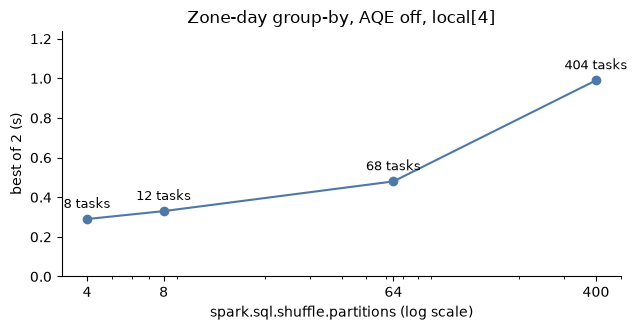

In [5]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
sp_rows = []
for n in [4, 8, 64, 400]:
    spark.conf.set("spark.sql.shuffle.partitions", str(n))
    secs = best_of(lambda: by_zone_day().collect())          # a new DataFrame per run: no shuffle reuse
    run_tagged(f"sp-{n}", lambda: by_zone_day().collect())
    m = metrics(f"sp-{n}")
    sp_rows.append({"shuffle partitions": n, "best s": round(secs, 2), "tasks": m["tasks"],
                    "shuffle write MB": m["shuffle write MB"]})
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.shuffle.partitions", "8")
sp = pd.DataFrame(sp_rows)
print(sp.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(sp["shuffle partitions"], sp["best s"], "o-", color="#4E79A7")
for x, y, t in zip(sp["shuffle partitions"], sp["best s"], sp.tasks):
    ax.annotate(f"{t} tasks", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set(xscale="log", xticks=sp["shuffle partitions"], xticklabels=sp["shuffle partitions"],
       title="Zone-day group-by, AQE off, local[4]", xlabel="spark.sql.shuffle.partitions (log scale)",
       ylabel="best of 2 (s)", ylim=(0, sp["best s"].max() * 1.25))
plt.tight_layout(); plt.show()

*Insight: With AQE off, 4 shuffle partitions gave the fastest run (0.29 s, 8 tasks) and 400 partitions the slowest (0.99 s, 404 tasks). The shuffle data was the same size in all runs (0.18-0.30 MB); the extra time is the fixed cost of 396 more tasks. On a cluster, a common start value is 2-3 tasks per core, with partitions of 100-200 MB; AQE then coalesces small partitions at run time.*

## 4. repartition vs. coalesce

| Method | Shuffle | Result | Typical use |
| :--- | :--- | :--- | :--- |
| `repartition(n)` | yes, round-robin | n partitions of equal size | more parallelism, even partitions |
| `repartition(n, "col")` | yes, hash of the column | equal keys in one partition | group or write by a key |
| `coalesce(n)` | no | merges existing partitions | fewer output files, cheap |

`coalesce` has no Exchange, so Spark merges it into the previous stage. A `coalesce(1)` makes the **whole stage**
run in one task. The cell compares plans. Then it writes one output file after a CPU-heavy step in two ways.
The step computes a SHA-512 hash of 5 columns of each row and keeps the rows whose hash starts with "00".

In [6]:
print("repartition(16):", [l.strip(" +-:")[:70] for l in plan(jan.repartition(16)).splitlines() if "Exchange" in l])
print("coalesce(2):    ", [l.strip(" +-:")[:70] for l in plan(jan.coalesce(2)).splitlines() if "Coalesce" in l or "Exchange" in l])

hashed = (jan.withColumn("h", F.sha2(F.concat_ws("|", "tpep_pickup_datetime", "PULocationID", "DOLocationID",
                                                    "trip_distance", "total_amount"), 512))
              .filter(F.col("h").startswith("00"))               # CPU-heavy step, small output (1 row in 256)
              .select("h", "PULocationID", "total_amount"))
for name, df in [("coalesce(1)", hashed.coalesce(1)), ("repartition(1)", hashed.repartition(1))]:
    out = str(WORK / name.replace("(", "_").replace(")", ""))
    _, secs = run_tagged(name, lambda df=df, out=out: df.write.mode("overwrite").parquet(out))
    m = metrics(name)
    print(f"{name:<15} {secs:5.2f} s, tasks: {m['tasks']:>2}, shuffle write: {m['shuffle write MB']:5.2f} MB, "
          f"output files: {len(list(Path(out).glob('*.parquet')))}")

repartition(16): ['Exchange RoundRobinPartitioning(16), REPARTITION_BY_NUM, [plan_id=2050']
coalesce(2):     ['Coalesce 2']


coalesce(1)      5.52 s, tasks:  1, shuffle write:  0.00 MB, output files: 1


repartition(1)   2.94 s, tasks:  5, shuffle write:  1.54 MB, output files: 1


*Insight: `coalesce(1)` took 5.52 s. It has no shuffle, so Spark ran the scan and the hash step in the same stage with 1 task: one core computed all 2.96 million hashes. `repartition(1)` took 2.94 s, about 1.9x faster. Its 4 scan tasks computed the hashes in parallel, and only the 1.54 MB of matching rows went through the shuffle to the 1 task that writes the file. Both wrote 1 output file. Use `coalesce` after cheap steps; use `repartition` when the step before it is expensive.*

Repartition by a column puts all rows of one key in the same partition. The data decides the sizes:

In [7]:
by_zone = jan.repartition(8, "PULocationID")
sizes = sorted((r["count"] for r in by_zone.groupBy(F.spark_partition_id()).count().collect()), reverse=True)
print("plan:", [l.strip(" +-:")[:70] for l in plan(by_zone).splitlines() if "Exchange" in l])
print("rows per partition:", [f"{s:,}" for s in sizes])
print(f"largest / smallest partition: {sizes[0] / sizes[-1]:.1f}x")
top = jan.groupBy("PULocationID").count().orderBy(F.desc("count")).limit(3).collect()
print("busiest pickup zones:", [(r["PULocationID"], f"{r['count']:,}") for r in top])

plan: ['Exchange hashpartitioning(PULocationID#7, 8), REPARTITION_BY_NUM, [pla']
rows per partition: ['574,145', '479,396', '445,761', '419,544', '378,254', '359,504', '211,261', '96,741']
largest / smallest partition: 5.9x


busiest pickup zones: [(132, '145,240'), (161, '143,469'), (237, '142,707')]


*Insight: Hash partitioning by zone gave partitions from 96,741 to 574,145 rows (5.9x). The three busiest pickup zones have more than 140,000 trips each, and hashing cannot split one key. One large partition makes one slow task, and the whole stage waits for it. This is **data skew**; Lesson 07 shows how to fix it.*

## 5. partitionBy, Partition Pruning and Small Files

`df.write.partitionBy("pickup_date")` writes one directory per value (`pickup_date=2024-01-15/`). A reader that
filters on the partition column opens only the matching directories: **partition pruning**. It is the same idea as
row-group skipping (Lesson 02), but at the level of directories, and it works without file statistics.

In [8]:
BY_DAY = str(WORK / "trips_by_day")
_, t_write = run_tagged("write-by-day",
                        lambda: jan.repartition("pickup_date").write.partitionBy("pickup_date").parquet(BY_DAY))
dirs = [d for d in Path(BY_DAY).iterdir() if d.is_dir()]
files = list(Path(BY_DAY).rglob("*.parquet"))
print(f"write: {t_write:.2f} s, {len(dirs)} directories, {len(files)} files, "
      f"{sum(f.stat().st_size for f in files) / 1e6:.1f} MB")
print("example:", sorted(str(f.relative_to(BY_DAY)) for f in files)[:2])

write: 6.77 s, 31 directories, 31 files, 60.9 MB
example: ['pickup_date=2024-01-01/part-00004-85258401-6c73-49bc-8133-8d03ebde34f8.c000.snappy.parquet', 'pickup_date=2024-01-02/part-00003-85258401-6c73-49bc-8133-8d03ebde34f8.c000.snappy.parquet']


In [9]:
def scan_metrics(action, tag):
    """Run an action; return its time and the metrics of its Parquet scan (REST API, SQL tab)."""
    before = {e["id"] for e in api("sql?length=10000&details=false")}
    _, secs = run_tagged(tag, action)
    time.sleep(0.5)
    new = [e for e in api("sql?length=10000&details=true&planDescription=false") if e["id"] not in before]
    scan = {}
    for e in new:
        for node in e["nodes"]:
            if node["nodeName"].startswith("Scan parquet"):
                scan.update({m["name"]: m["value"] for m in node["metrics"]})
    return secs, scan

pruning = []
for name, df in [("all days", spark.read.parquet(BY_DAY)),
                 ("pickup_date = 2024-01-15", spark.read.parquet(BY_DAY).filter(F.col("pickup_date") == "2024-01-15"))]:
    act = lambda df=df: df.agg(F.count("*"), F.sum("total_amount")).collect()
    act()                                                     # warm-up
    secs, scan = scan_metrics(act, f"prune-{name}")
    pf = [l.strip() for l in plan(df.agg(F.count("*"))).split(", ") if l.startswith("PartitionFilters")]
    pruning.append({"read": name, "time s": round(secs, 2), "files read": scan.get("number of files read"),
                    "partitions read": scan.get("number of partitions read"),
                    "size of files read": scan.get("size of files read"), "rows": scan.get("number of output rows")})
    print(f"{name:<26} {pf[0][:100] if pf else ''}")
print(pd.DataFrame(pruning).to_string(index=False))

all days                   PartitionFilters: []


pickup_date = 2024-01-15   PartitionFilters: [isnotnull(pickup_date#1118)
                    read  time s files read partitions read size of files read      rows
                all days    0.30         31              31           58.1 MiB 2,964,606
pickup_date = 2024-01-15    0.08          1               1         1623.7 KiB    77,033


*Insight: With the filter on the partition column, Spark read 1 of 31 files. It read 1,623.7 KiB instead of 58.1 MiB, and 77,033 rows instead of 2,964,606. The query took 0.08 s instead of 0.30 s. The plan shows the filter under `PartitionFilters`: Spark removed the other 30 directories before it started a task.*

**The small-files problem.** Each task writes one file for every partition value that it holds. If many tasks
hold rows of every day, the table gets many small files. Each file costs a file-open, a footer read and a task
slice on every later read, and object stores charge per request. The table above was written after `repartition("pickup_date")`:
all rows of one day were in one task, so each day got one file. The cell writes the same data after
`repartition(64)` (round-robin: every task holds rows of every day). Then it reads both layouts with the same aggregation.

                                           files  avg file KB  total MB  write s  read best of 2 s
repartition(64) + partitionBy             1984.0         48.3      95.7    17.82              1.86
repartition("pickup_date") + partitionBy    31.0       1964.3      60.9     6.77              0.23


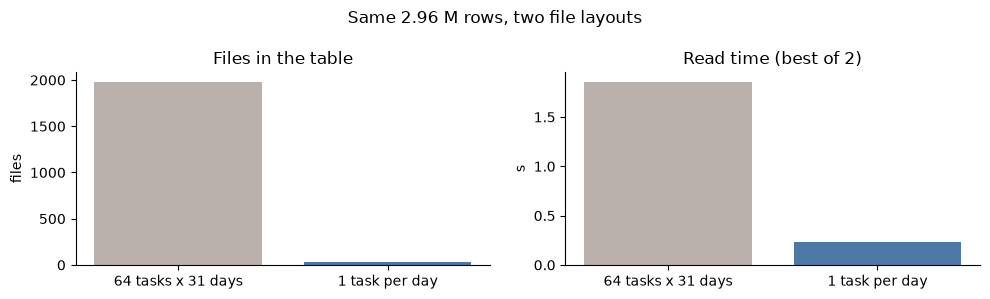

In [10]:
SMALL = str(WORK / "trips_by_day_small_files")
_, t_small = run_tagged("write-small", lambda: jan.repartition(64).write.partitionBy("pickup_date").parquet(SMALL))
layouts = {}
for name, out, t_w in [("repartition(64) + partitionBy", SMALL, t_small),
                       ('repartition("pickup_date") + partitionBy', BY_DAY, t_write)]:
    fs = list(Path(out).rglob("*.parquet"))
    read = lambda out=out: spark.read.parquet(out).groupBy("PULocationID").agg(F.sum("total_amount")).collect()
    layouts[name] = {"files": len(fs), "avg file KB": round(sum(f.stat().st_size for f in fs) / len(fs) / 1e3, 1),
                     "total MB": round(sum(f.stat().st_size for f in fs) / 1e6, 1),
                     "write s": round(t_w, 2), "read best of 2 s": round(best_of(read), 2)}
layouts = pd.DataFrame(layouts).T
print(layouts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
labels = ["64 tasks x 31 days", "1 task per day"]
for ax, col, title, unit in zip(axes, ["files", "read best of 2 s"], ["Files in the table", "Read time (best of 2)"], ["files", "s"]):
    ax.bar(labels, layouts[col].astype(float), color=["#BAB0AC", "#4E79A7"])
    ax.set(title=title, ylabel=unit)
fig.suptitle("Same 2.96 M rows, two file layouts"); plt.tight_layout(); plt.show()

*Insight: The round-robin layout wrote 1,984 files (64 tasks x 31 days) of 48.3 KB on average. The other layout has 31 files of about 1.96 MB. The same rows took 95.7 MB instead of 60.9 MB, because every small file has its own footer and compresses less well. The write took 17.82 s instead of 6.77 s. The read took 1.86 s instead of 0.23 s, about 8x slower.*

| Rule of thumb | Why |
| :--- | :--- |
| Partition by a column with few values that queries filter on (date, region) | pruning skips whole directories |
| Do not partition by a column with many values (user id, trip id) | millions of tiny directories and files |
| Aim for files of about 100 MB to 1 GB | fewer opens and footers per byte read |
| `repartition(col)` before `partitionBy(col)`, or compact later | one file per partition value |

## Real-World Use Case or Analogy

A shuffle is like **sorting mail at a post office**. Each truck (task) brings a mixed bag of letters (rows). To
deliver by street (key), every letter must go to the sorter for its street, and that costs time for every letter.
If each truck first bundles the letters per street (partial aggregation), much less mail moves. Partitioning a table
by date is like a filing cabinet with one drawer per day: to find one day, you open one drawer.

Most data platforms partition their large tables by date (`dt=2024-01-15`), and daily jobs read only the newest
partitions. Table formats such as Delta Lake and Iceberg (M12) add compaction (`OPTIMIZE`) to fix small files, and
Iceberg's hidden partitioning removes the need to filter on a separate date column.

In [11]:
spark.stop()